# PRCP-1013: Walk vs Run Classification

**Objective:** Analyze wearable motion-sensor readings and train machine-learning models to classify walking/running activity labels.

Run notebook cells from top to bottom. Upload `walkrun.csv` to the Colab Files panel before running the data-loading cell.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import LinearSVC

import warnings
warnings.filterwarnings('ignore')


In [5]:
# Load the dataset
# Upload walkrun.csv to the Colab Files panel before running this cell.
df = pd.read_csv('/content/walkrun.csv')
print('Dataset loaded successfully!')
print('Shape:', df.shape)

Dataset loaded successfully!
Shape: (88588, 11)


In [6]:
display(df.head())
display(df.tail())

,date,time,username,wrist,activity,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
0,2017-6-30,13:51:15:847724020,viktor,0,0,0.2650,-0.7814,-0.0076,-0.0590,0.0325,-2.9296
1,2017-6-30,13:51:16:246945023,viktor,0,0,0.6722,-1.1233,-0.2344,-0.1757,0.0208,0.1269
2,2017-6-30,13:51:16:446233987,viktor,0,0,0.4399,-1.4817,0.0722,-0.9105,0.1063,-2.4367
3,2017-6-30,13:51:16:646117985,viktor,0,0,0.3031,-0.8125,0.0888,0.1199,-0.4099,-2.9336
4,2017-6-30,13:51:16:846738994,viktor,0,0,0.4814,-0.9312,0.0359,0.0527,0.4379,2.4922


,date,time,username,wrist,activity,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
88583,2017-7-9,20:9:15:317911028,viktor,0,0,0.3084,-0.8376,-0.1327,0.4823,2.0124,0.6048
88584,2017-7-9,20:9:15:517889022,viktor,0,0,0.4977,-1.0027,-0.4397,0.1022,-1.2565,-0.0761
88585,2017-7-9,20:9:15:717828989,viktor,0,0,0.4587,-1.1780,-0.2827,-1.4500,-0.2792,-1.2616
88586,2017-7-9,20:9:15:917932987,viktor,0,0,0.2590,-0.8582,-0.0759,-1.5165,0.4560,-1.7755
88587,2017-7-9,20:9:16:117410004,viktor,0,0,0.3140,-0.8008,-0.0911,0.1183,1.0850,1.2814


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88588 entries, 0 to 88587
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            88588 non-null  object 
 1   time            88588 non-null  object 
 2   username        88588 non-null  object 
 3   wrist           88588 non-null  int64  
 4   activity        88588 non-null  int64  
 5   acceleration_x  88588 non-null  float64
 6   acceleration_y  88588 non-null  float64
 7   acceleration_z  88588 non-null  float64
 8   gyro_x          88588 non-null  float64
 9   gyro_y          88588 non-null  float64
 10  gyro_z          88588 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 7.4+ MB


In [8]:
df.shape

(88588, 11)

In [9]:
df.describe()

,wrist,activity,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
count,88588.000000,88588.000000,88588.000000,88588.000000,88588.000000,88588.000000,88588.000000,88588.000000
mean,0.522170,0.500801,-0.074811,-0.562585,-0.313956,0.004160,0.037203,0.022327
std,0.499511,0.500002,1.009299,0.658458,0.486815,1.253423,1.198725,1.914423
min,0.000000,0.000000,-5.350500,-3.299000,-3.753800,-4.430600,-7.464700,-9.480000
25%,0.000000,0.000000,-0.381800,-1.033500,-0.376000,-0.920700,-0.644825,-1.345125
50%,1.000000,1.000000,-0.059500,-0.759100,-0.221000,0.018700,0.039300,0.006900
75%,1.000000,1.000000,0.355500,-0.241775,-0.085900,0.888800,0.733700,1.398200
max,1.000000,1.000000,5.603300,2.668000,1.640300,4.874200,8.498000,11.266200


In [10]:
print(df.isnull().sum())

date              0
time              0
username          0
wrist             0
activity          0
acceleration_x    0
acceleration_y    0
acceleration_z    0
gyro_x            0
gyro_y            0
gyro_z            0
dtype: int64


In [11]:
print("duplicates:",df.duplicated().sum())

duplicates: 0


In [12]:
df = df.drop_duplicates()

In [13]:
df.dtypes

,0
date,object
time,object
username,object
wrist,int64
activity,int64
acceleration_x,float64
acceleration_y,float64
acceleration_z,float64
gyro_x,float64
gyro_y,float64


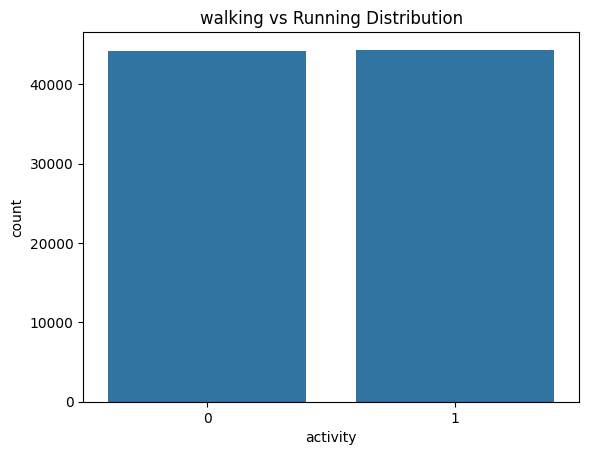

In [14]:
sns.countplot(data=df, x='activity')
plt.title('walking vs Running Distribution')
plt.xlabel('activity')
plt.ylabel('count')

plt.show()

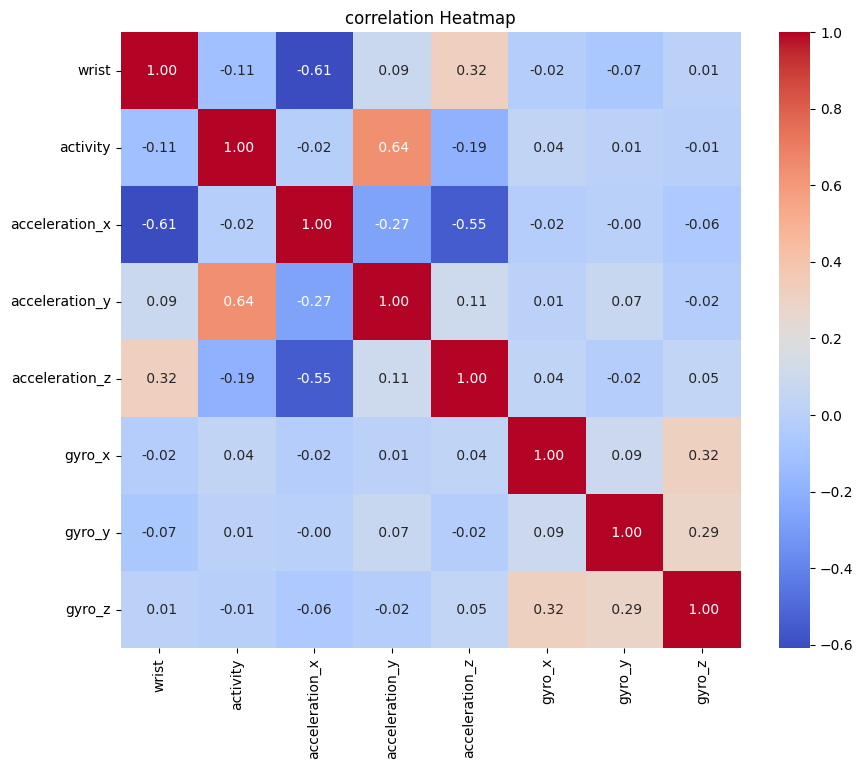

In [15]:
numeric_df = df.select_dtypes(include=[np.number])
plt.figure(figsize=(10, 8))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt=' .2f'
)
plt.title('correlation Heatmap')
plt.show()

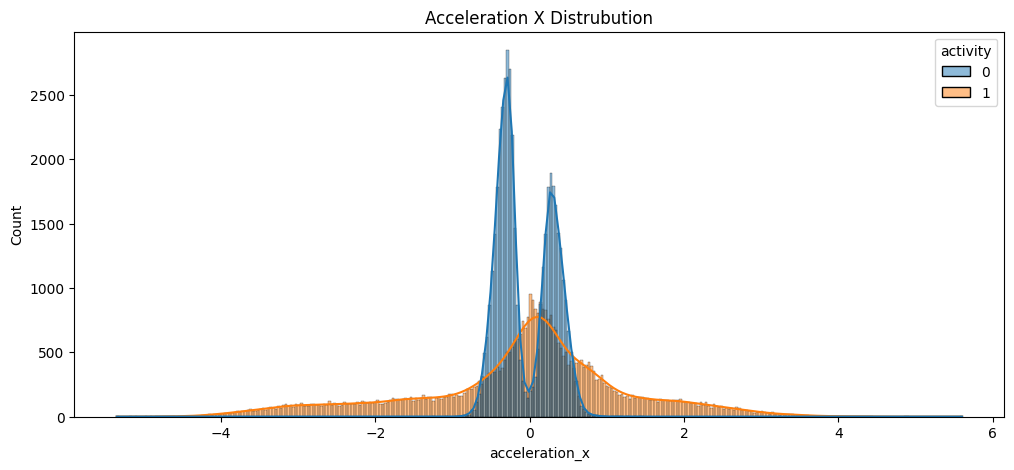

In [16]:
plt.figure(figsize=(12, 5))
sns.histplot(
    data=df,
    x='acceleration_x',
    hue='activity',
    kde=True
)
plt.title('Acceleration X Distrubution')
plt.show()

In [17]:
X = df[
    [
        'wrist',
        'acceleration_x',
        'acceleration_y',
        'acceleration_z',
        'gyro_x',
        'gyro_y',
        'gyro_z',
    ]
]
y = df['activity']

In [18]:
# Split into training and testing data (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Training data:', X_train.shape)
print('Testing data:', X_test.shape)

Training data: (70870, 7)
Testing data: (17718, 7)


In [19]:
# Standardize sensor values for models that need scaled features.
# Fit only on training data to avoid data leakage.
scaler = StandardScaler()
X_train_scaler = scaler.fit_transform(X_train)
X_test_scaler = scaler.transform(X_test)
print('Scaled training shape:', X_train_scaler.shape)
print('Scaled testing shape:', X_test_scaler.shape)

Scaled training shape: (70870, 7)
Scaled testing shape: (17718, 7)


In [20]:
# Train and evaluate classical ML models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Linear SVM': LinearSVC(max_iter=3000, random_state=42)
}
results = []
trained_models = {}
model_predictions = {}
for name, model_obj in models.items():
    if name in ['Logistic Regression', 'SVM']:
        model_obj.fit(X_train_scaler, y_train)
        predictions = model_obj.predict(X_test_scaler)
    else:
        model_obj.fit(X_train, y_train)
        predictions = model_obj.predict(X_test)
    trained_models[name] = model_obj
    model_predictions[name] = predictions
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, predictions, average='weighted', zero_division=0),
        'F1 Score': f1_score(y_test, predictions, average='weighted', zero_division=0)
    })
results_df = pd.DataFrame(results).sort_values('Accuracy', ascending=False).reset_index(drop=True)
display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.991421,0.991422,0.991421,0.991421
1,Decision Tree,0.986003,0.986004,0.986003,0.986003
2,Gradient Boosting,0.984028,0.984088,0.984028,0.984027
3,Linear SVM,0.864996,0.869540,0.864996,0.864594
4,Logistic Regression,0.863924,0.867174,0.863924,0.863634


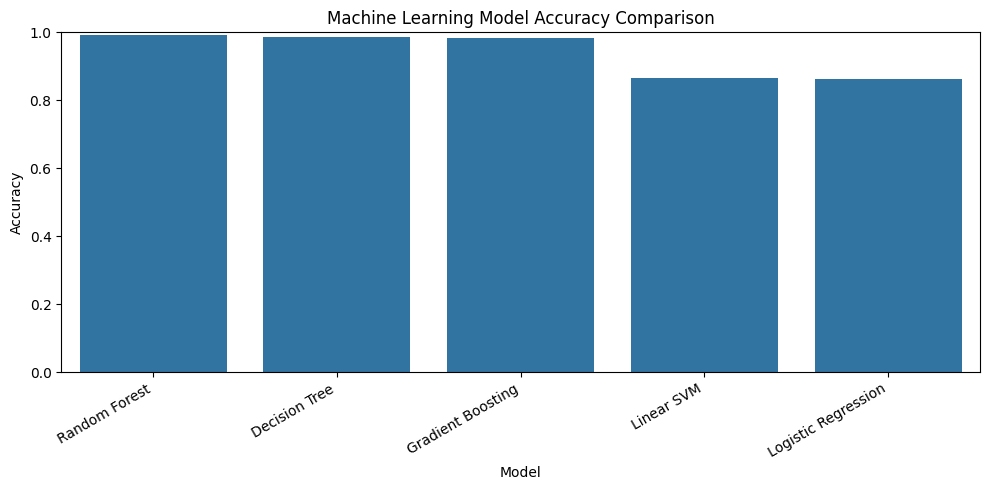

In [21]:
# Accuracy comparison chart
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x='Model', y='Accuracy')
plt.title('Machine Learning Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [22]:
# TensorFlow is usually pre-installed in Google Colab.
# If import fails, uncomment the next line, run it, and restart the runtime.
# !pip install tensorflow

In [23]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

y_train_nn = y_train.astype('float32')
y_test_nn = y_test.astype('float32')
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaler.shape[1],)),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history = model.fit(
    X_train_scaler, y_train_nn, epochs=20, batch_size=32,
    validation_split=0.2, callbacks=[early_stop], verbose=1
)

Epoch 1/20
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9660 - loss: 0.0912 - val_accuracy: 0.9905 - val_loss: 0.0310
Epoch 2/20
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9876 - loss: 0.0396 - val_accuracy: 0.9920 - val_loss: 0.0278
Epoch 3/20
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9887 - loss: 0.0347 - val_accuracy: 0.9925 - val_loss: 0.0267
Epoch 4/20
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9898 - loss: 0.0316 - val_accuracy: 0.9915 - val_loss: 0.0271
Epoch 5/20
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9904 - loss: 0.0294 - val_accuracy: 0.9914 - val_loss: 0.0272
Epoch 6/20
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9908 - loss: 0.0279 - val_accuracy: 0.9921 - val_loss: 0.0254
Epoch 7/20
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9909 - loss: 0.0277 - val_accuracy: 0.9929 - val_loss: 0.0238
Epoch 8/20
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9910 - loss: 0.0272 - 

In [24]:
loss, accuracy = model.evaluate(X_test_scaler, y_test_nn)

print("Test Accuracy:", accuracy)
print("Test Loss:", loss)

554/554 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9925 - loss: 0.0229
Test Accuracy: 0.9925499558448792
Test Loss: 0.022903408855199814


In [25]:
# Neural Network predictions
probabilities = model.predict(X_test_scaler, verbose=0)
nn_predictions = (probabilities >= 0.5).astype(int).flatten()
print(classification_report(y_test_nn, nn_predictions, zero_division=0))

              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99      8845
         1.0       0.99      0.99      0.99      8873

    accuracy                           0.99     17718
   macro avg       0.99      0.99      0.99     17718
weighted avg       0.99      0.99      0.99     17718



In [26]:
# Add Neural Network scores to the comparison table
nn_accuracy = accuracy_score(y_test_nn, nn_predictions)
nn_precision = precision_score(y_test_nn, nn_predictions, average='weighted', zero_division=0)
nn_recall = recall_score(y_test_nn, nn_predictions, average='weighted', zero_division=0)
nn_f1 = f1_score(y_test_nn, nn_predictions, average='weighted', zero_division=0)
results_df = pd.concat([results_df, pd.DataFrame([
    {'Model': 'Neural Network', 'Accuracy': nn_accuracy, 'Precision': nn_precision,
     'Recall': nn_recall, 'F1 Score': nn_f1}
])], ignore_index=True).sort_values('Accuracy', ascending=False).reset_index(drop=True)
display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,Neural Network,0.992550,0.992558,0.992550,0.992550
1,Random Forest,0.991421,0.991422,0.991421,0.991421
2,Decision Tree,0.986003,0.986004,0.986003,0.986003
3,Gradient Boosting,0.984028,0.984088,0.984028,0.984027
4,Linear SVM,0.864996,0.869540,0.864996,0.864594
5,Logistic Regression,0.863924,0.867174,0.863924,0.863634


In [27]:
# Neural Network classification report
print(classification_report(y_test_nn, nn_predictions, zero_division=0))

              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99      8845
         1.0       0.99      0.99      0.99      8873

    accuracy                           0.99     17718
   macro avg       0.99      0.99      0.99     17718
weighted avg       0.99      0.99      0.99     17718



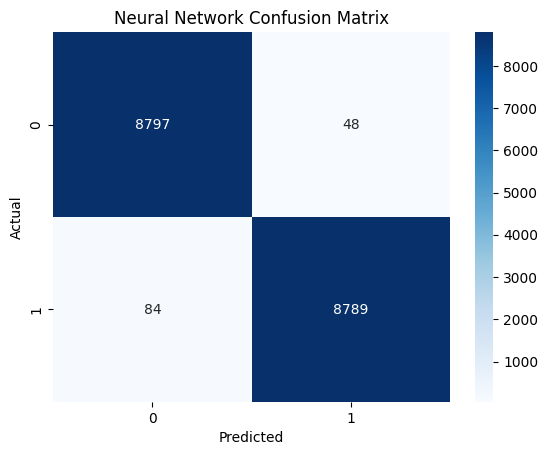

In [28]:
cm = confusion_matrix(y_test_nn, nn_predictions)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Neural Network Confusion Matrix')
plt.show()

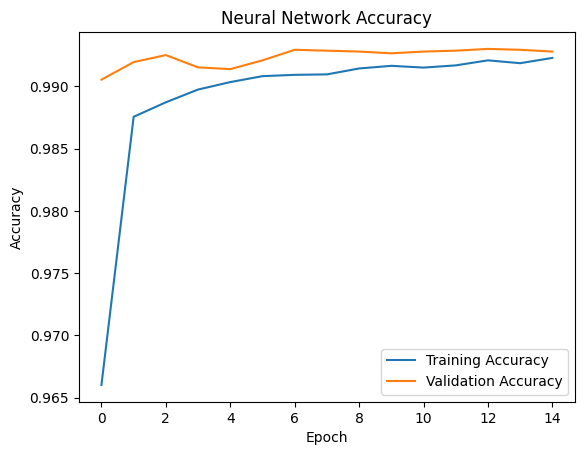

In [29]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Neural Network Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


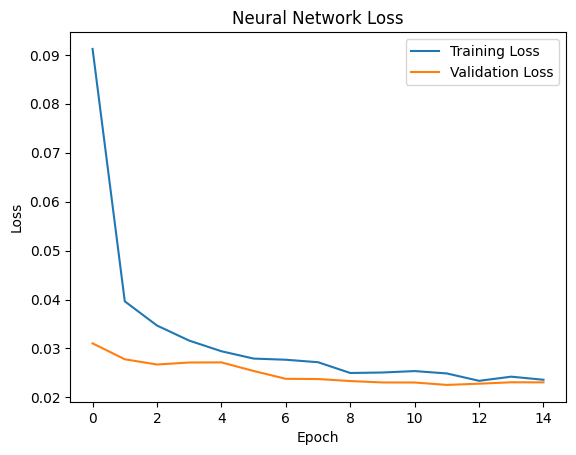

In [30]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Neural Network Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Model Comparison Report

The table compares Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, SVM, and Neural Network using Accuracy, Precision, Recall, and F1-score. Use the measured results to select a model; do not assume a model is best before testing. The confusion matrix and F1-score should also be reviewed, not accuracy alone.

In [31]:
# Automatically identify the top model by F1-score, then accuracy
best_row = results_df.sort_values(['F1 Score', 'Accuracy'], ascending=False).iloc[0]
print('Best model:', best_row['Model'])
print(f"Accuracy: {best_row['Accuracy']:.4f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall: {best_row['Recall']:.4f}")
print(f"F1 Score: {best_row['F1 Score']:.4f}")

Best model: Neural Network
Accuracy: 0.9925
Precision: 0.9926
Recall: 0.9925
F1 Score: 0.9925


# Challenges Faced and Solutions

**1. Understanding sensor data**

Challenge: The dataset contains raw acceleration and gyroscope values which were difficult to understand initially.

Solution: Exploratory Data Analysis and visualization were used to understand sensor distributions and activity patterns.

**2. Data preprocessing**

Challenge: Sensor variables have different scales and formats.

Solution: StandardScaler was used to standardize the numerical features before training suitable machine learning models.

**3. Model selection**

Challenge: Selecting the most suitable machine learning algorithm.

Solution: Multiple models were trained and compared using accuracy, precision, recall, and F1-score.

**4. Overfitting**

Challenge: Some models may memorize training data instead of learning general patterns.

Solution: Train/test evaluation, validation data, and Dropout in the neural network were used to help reduce overfitting.

**5. Model evaluation**

Challenge: Accuracy alone may not fully explain model performance.

Solution: Classification reports and confusion matrices were used to examine classification errors and other performance metrics.

# Conclusion

The Walk and Run Classification project demonstrates how machine learning can be used to recognize human physical activities using wearable motion sensor data.

The dataset contains acceleration and gyroscope measurements that provide information about human movement. Data analysis was performed to understand the dataset and identify patterns.

Multiple machine learning algorithms and a multi-layer neural network were trained and evaluated. Their performance was compared using accuracy, precision, recall, F1-score, and confusion matrices.

The best-performing model was identified based on experimental results. This project demonstrates the use of data analysis, preprocessing, machine learning, and model evaluation to develop an activity classification system.